In [1]:
import sys, time, tempfile
from pathlib import Path
ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p/'C'/'evoca.h').exists())
sys.path.insert(0, str(ROOT/'python'))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import bifurcation as bif
import evoca_explore as ee
from evoca_py import EvoCA
from evoca_nb import rgb, export_recipe_once   # shared notebook helpers: python/evoca_nb.py
WS = 'Criticality-bifurcation'
T0 = time.time()

# Criticality-bifurcation: lab notebook

**Question.** Where are EvoCA's dynamical transitions as control parameters vary (bifurcation diagrams of global time series such as population and activity), and what characterizes them?

Framing (N's established positions): ruggedness is emergent in EvoCA (no NK-style knob); critical exponents are not only a finite-size-scaling question, so a bifurcation-diagram program over control parameters is preferred; Feigenbaum period-doubling has **not** been observed in EvoCA and is not presumed (the `feigenbaum_delta` helper exists but we say "bifurcation" generally).

Links: [`digests/`](digests/) (none yet) and [`Scans/`](Scans/) (none yet; this workstream owns no scans until the first torque sweep). Source of the viability bracket used below: the standard-model rescan [`../Resource-driving/Scans/2026-10-23_R1_mscale_bracket_standard/`](../Resource-driving/Scans/2026-10-23_R1_mscale_bracket_standard/) of R1 (protocol: [`../Resource-driving/Scans/2026-05-18_R1_mscale_bracket/notes.md`](../Resource-driving/Scans/2026-05-18_R1_mscale_bracket/notes.md)).

**Running the examples interactively.** After each example run there is a code cell of commented-out lines that open the same configuration in the interactive SDL window (`run_with_controls`, from `python/controls.py`). Uncomment and run it to watch the simulation; it is commented out so that *Run All* never blocks on a window. Only one EvoCA lattice exists at a time, so this replaces any simulation still alive in the kernel. 

**Eating rule.** Every run here uses the standard model, the capped mouthful (`food_cap=1`, the A9 fix): a cell never eats more food than its site holds. All example runs have `m_scale` 3.5, where the cap binds, so the 2026-10-15 outputs (legacy rule) moved materially when the notebook was re-executed on 2026-10-23. The old-vs-new comparison is in the final section, *Legacy rule (`food_cap=0`): results that depend on it*.

Snapshot of `ISSUES.md` as of the last execution of this notebook. `ISSUES.md` is the source; edit it there, not here.

In [2]:
display(Markdown((ROOT/'Research'/WS/'ISSUES.md').read_text()))

# Criticality-bifurcation: issues and directions
_Updated 2026-10-23_

## Decisions needed (N)
- **CRIT-D1**: First control parameter, range and N for the torque campaign — options: (a) `food_inc` 0.003-0.06 fine grid, densest at 0.003-0.007 (extinction) and 0.014-0.019 (amplitude collapse) (the free-energy source; Phi is its natural partner; the example diagram shows extinction, boom-bust, amplitude collapse and saturation inside this range), (b) `m_scale` 1.5-6, (c) both as a 2-D map. Recommend (a) first at fixed values (m_scale 3.5, tax 0.035, mu_lut 0.06, gdiff 0.06), then (b) at food_inc 0.018. 2026-10-23: range lowered from 0.010-0.06 because under the standard rule (`food_cap=1`) extinction moved from <= 0.011 to <= 0.005 (N=64), and the legacy R1 rationale for (b) (U-shaped viability in `m_scale`) does not survive the standard rescan `Resource-driving/Scans/2026-10-23_R1_mscale_bracket_standard`. Blocks CRIT-N1.
- **CRIT-D2**: What counts as a transition (a pre-registered criterion, so a "flat diagram" is a valid outcome) — recommend all of: extinction boundary (fraction of replicate seeds extinct crosses 0.5), onset of sustained oscillation (spectral peak above a noise floor, not the raw extrema count), amplitude collapse (tail std/mean falling through a threshold), and, for any candidate, an N-scaling test. Blocks CRIT-N1/N4.

## Open questions
- **CRIT-Q1**: Is the observed boom-bust oscillation a finite-size synchronized-lattice cycle (relative amplitude decays with N) or intrinsic? 2026-10-23, standard rule, single-seed example check (notebook): the large-amplitude cycle at food_inc 0.016 persists with N (std/N^2 0.252, 0.179, 0.217 at N=32/64/128, non-monotone; legacy values were 0.335, 0.318, 0.297) while the small-amplitude regime at 0.022 shrinks as 1/N (relative amplitude 0.041, 0.019, 0.0097); neither is replicated, and 0.016 sits next to the amplitude collapse (0.015-0.017), so the test should be repeated inside the boom-bust window (e.g. 0.013). Decides whether diagram columns mean anything in the thermodynamic limit; couples to the Docs/EvoCA_research_directions.md §5 H_critical / H_ceiling question (xi ~ N/3 plateau).
- **CRIT-Q2**: Is `recurrent_extrema` the right reducer for noisy, irregular-amplitude series? In the example runs the extrema count ranges from 13 (a regular boom-bust cycle at 0.013) to over 200 (noise at 0.020), and at 0.005 and 0.017 the extrema fill a band, so the count cannot distinguish limit cycle from irregular dynamics. Candidates: autocorrelation/spectral peak, return map of successive maxima, Poincare-section sampling, largest-Lyapunov-style divergence of nearby seeds. See `python/bifurcation.py` `recurrent_extrema`.
- **CRIT-Q3**: Which side of any boundary is a bifurcation in the dynamical sense versus a stochastic extinction (absorbing-state) transition? EvoCA has an absorbing state (pop=0), so the extinction edge may belong to the directed-percolation-like class rather than a deterministic bifurcation; the R1 extinction table (m_scale x food_inc) is endpoint data only. 2026-10-23: in the standard-rule example runs extinction happens at the first crash after the initial boom (ticks 104-139), not after sustained cycling.
- **CRIT-Q4**: Hysteresis: does ramping `food_inc` up versus down give different columns (the directions doc, R3 (c), suggests a slow ramp as an alternative to a fixed grid)? Untested; needs a ramp driver (CRIT-N3).
- **CRIT-Q5**: Does evolution matter? Runs with `mu_lut=0` freeze the substrate (see memory notes on frozen rich substrates); compare mu_lut=0 against mu_lut>0 columns to separate ecological (food-limited) oscillation from evolutionary change.

## Next directions
- **CRIT-N1**: Real `food_inc` bifurcation campaign — campaign (torque), N in {64, 128, 256}, 8000+ ticks, 41+ values x >=5 seeds, observable `pop` first; blocked on CRIT-D1/D2. Uses `python/bifurcation.py` `sweep` unchanged.
- **CRIT-N2**: Multi-observable harness — needs dev (small, Python only): extend `scalar_series` to record Phi (`get_dissipation`), births/deaths, `dyn_activity` total, `A_new` (needs neutral shadow, computed as in `evoca_explore.run_sim`), `lut_div`, lineage return; the example notebook has a working per-tick `record()` prototype. Cross-ref checkpoint actions G1 (A_new), L1 (Phi), D2/D3 (lineage return).
- **CRIT-N3**: Slow-ramp / hysteresis driver — needs dev (Python): change `food_inc` (or `m_scale`) during a run through the live sim attribute instead of re-initializing, up and down.
- **CRIT-N4**: Control-parameter and finite-size follow-up on whichever transition passes CRIT-D2 — analysis/campaign: order parameter = alive density or oscillation amplitude, susceptibility, Binder cumulant across N; fixes the Q1 H_critical / H_ceiling question (directions doc §5, R3 (a)/(b)).
- **CRIT-N5**: Second axes — campaign: `m_scale` (R1 optimum), `tax`, `mu_lut`, then a 2-D map (m_scale x food_inc); start from the standard R1 rescan (`Resource-driving/Scans/2026-10-23_R1_mscale_bracket_standard/results.csv`) to pre-select regions (2026-10-23: the legacy R1 non-monotone viability that motivated the map is not present in the rescan).
- **CRIT-N6**: Replace the reducer's raw extrema count by a classifier (fixed point / periodic / irregular / extinct / saturated) for sweep summaries — needs dev; feeds CRIT-Q2. Keep `feigenbaum_delta` but do not report it unless a clean cascade appears.

## Parked
- Feigenbaum delta extraction: period-doubling has not been observed in EvoCA (N's position); helper retained, not used.
- Motility-related parameters: motility branch on hold (memory, 2026-07-19).


## 2026-05-16: harness built (S2e)

**Question.** Can EvoCA's global time series be reduced to a bifurcation diagram without touching the C core?

**What was done.** Agent S2e (commit `dfdb010`, archived in [`../research_board_archival.md`](../research_board_archival.md)) added `python/bifurcation.py`: `scalar_series` (per-tick observable, same init sequence as `run_sim`), `recurrent_extrema` (post-transient local extrema, clustered), `sweep`, `to_scatter`, plus a best-effort `feigenbaum_delta` / `doubling_thresholds`. `tests/test_bifurcation.py` checks the reducer on synthetic fixed-point / period-2 / period-4 series. The `--demo` (food_inc 0.02-0.20, N=48, 400 steps) was a format check only; **no scientific sweep was ever run** (board: "no sweeps launched yet").

**Directions that came out of it.** Docs/EvoCA_research_directions.md §5 plus the NP reply R3 split the exponent questions into three programs: (c) bifurcations of global dynamics (preferred, cheap), (b) control-parameter exponents at fixed N, (a) finite-size scaling only as the xi ~ N/3 plateau discriminator (Binder cumulant / susceptibility). Priority stated there: (c) > (b) > (a).

## 2026-05-18: R1 viability bracket (input from Resource-driving)

R1 (`Resource-driving/Scans/2026-05-18_R1_mscale_bracket`, N=256, 8000 ticks, 300 configs) bracketed `m_scale` and `food_inc`. Its recorded finding (U-shaped viability in `m_scale`, `food_inc` <= 0.010 lethal at m_scale 2.5/3.5) was measured under the legacy rule and does not survive the standard rule; see the final section. **2026-10-23:** R1 was rescanned under the standard rule with the same configs and protocol (`2026-10-23_R1_mscale_bracket_standard`); the table below reads the rescan. These are *endpoint* statistics (extinct yes/no, means), not time-series dynamics, so they locate where to look but say nothing about oscillation vs fixed point.


In [3]:
r1 = pd.read_csv(ROOT/'Research/Resource-driving/Scans/2026-10-23_R1_mscale_bracket_standard/results.csv')
print('standard-model rescan, food_cap =', sorted(r1.param_food_cap.unique()))
print('extinct fraction by (m_scale, food_inc):')
display(r1.groupby(['param_m_scale','param_food_inc']).extinct.mean().unstack().round(2))
print('R1 held tax in', sorted(r1.param_tax.unique()), ' mu_lut in', sorted(r1.param_mu_lut.unique()), ' gdiff in', sorted(r1.param_gdiff.unique()))

standard-model rescan, food_cap = [np.int64(1)]
extinct fraction by (m_scale, food_inc):


param_food_inc,0.005,0.008,0.010,0.013,0.018
param_m_scale,,,,,
2.5,0.48,0.17,0.00,0.0,0.0
3.5,0.23,0.05,0.11,0.0,0.0
5.0,0.37,0.05,0.00,0.0,0.0


R1 held tax in [np.float64(0.03), np.float64(0.035), np.float64(0.04)]  mu_lut in [np.float64(0.01), np.float64(0.03), np.float64(0.06), np.float64(0.1), np.float64(0.15)]  gdiff in [np.float64(0.05), np.float64(0.06), np.float64(0.08)]


**Observed (standard rescan; cells hold 12-26 configs over tax / mu_lut / gdiff).** Extinction occurs only at `food_inc` <= 0.010 and nowhere exceeds 0.48. At m_scale 3.5 the extinct fraction is 0.23 / 0.05 / 0.11 at food_inc 0.005 / 0.008 / 0.010 and 0 from 0.013 up. At food_inc 0.005 it is 0.48 / 0.23 / 0.37 at m_scale 2.5 / 3.5 / 5.0, so the legacy U-shape (worst at intermediate `m_scale`) is gone; with ~20 configs per cell the remaining differences are not resolved.


**Choice (2026-10-15; rationale revised 2026-10-23).** `food_inc` is the first control parameter: it is the direct free-energy source (Phi, the dissipation per capita, is its natural partner). Under the standard rule the m_scale 3.5 extinction boundary lies at or below food_inc 0.005-0.010 (R1 rescan above), so the example sweep starts at 0.003. Fixed other parameters for all example runs: `m_scale=3.5, tax=0.035, mu_lut=0.06, gdiff=0.06` (mid-values of R1's tax/mu_lut/gdiff grids). Init, seeds and egenome follow `run_sim` (GoL LUT, egenome 0b000011, halfplane alive). N=64, 3000 ticks, transient 50%.


## 2026-10-15: first bifurcation diagram (food_inc), example runs

**Question.** Does the post-transient population time series change character (extinct / oscillating / steady / saturated) across the extinction boundary region of `food_inc`?

**What was done.** Twelve values of `food_inc`, two seeds, `bif.sweep` with observable `pop`. The four lowest values (0.003-0.009) were added on 2026-10-23: under the standard rule 0.011, the lowest 2026-10-15 value, no longer goes extinct. Everything below is *observed in these example runs, N=64, not a campaign result*.


In [4]:
BASE = dict(m_scale=3.5, tax=0.035, mu_lut=0.06, gdiff=0.06, food_cap=1)   # standard (capped) rule, explicit
VALUES = [0.003, 0.005, 0.007, 0.009, 0.011, 0.013, 0.015, 0.017, 0.020, 0.024, 0.030, 0.050]
N, NSTEPS = 64, 3000
res = {}
for seed in (0, 1):
    res[seed] = bif.sweep('food_inc', VALUES, base_params=BASE, observable='pop',
                          n_steps=NSTEPS, N=N, seed=seed, transient_frac=0.5)
rows = []
for seed in res:
    for r in res[seed]:
        rows.append(dict(seed=seed, food_inc=r['value'], n_recurrent=r['n_recurrent'],
                         tail_mean=round(r['mean'],1), tail_std=round(r['series_tail_std'],1),
                         min=r['points'].min(), max=r['points'].max()))
tab = pd.DataFrame(rows); display(tab)

,seed,food_inc,n_recurrent,tail_mean,tail_std,min,max
0,0,0.003,1,0.0,0.0,0.0,0.0
1,0,0.005,64,556.6,462.4,33.0,2116.0
2,0,0.007,17,652.5,792.5,16.0,2685.0
3,0,0.009,16,860.2,1002.4,15.5,3097.0
4,0,0.011,15,1075.0,1198.2,36.0,3579.0
5,0,0.013,13,1308.2,1318.3,97.6,3712.0
6,0,0.015,16,1609.2,1291.5,278.0,3832.0
7,0,0.017,106,1991.1,376.8,1238.0,3036.0
8,0,0.020,238,2338.3,79.4,2166.0,2514.0
9,0,0.024,138,2803.9,31.7,2725.0,2894.0


In [5]:
# extinct runs: tick of extinction (pop first reaches 0)
for seed in res:
    for r in res[seed]:
        if r['mean'] == 0:
            s = bif.scalar_series(dict(BASE, food_inc=r['value']), N=N, n_steps=NSTEPS, seed=seed)
            print(f"seed {seed}, food_inc {r['value']}: extinct at tick {int(np.argmax(s == 0))}")


seed 0, food_inc 0.003: extinct at tick 104
seed 1, food_inc 0.003: extinct at tick 139


seed 1, food_inc 0.005: extinct at tick 113


In [6]:
# The simulation may be run interactively with the following
# (commented out so that "Run All" does not block on the SDL window):
# from controls import run_with_controls
# sim = ee.build_sim(dict(BASE, food_inc=0.017), N=128, seed=0)   # any value in VALUES
# run_with_controls(sim, cell_px=4, probes={'ts': True})

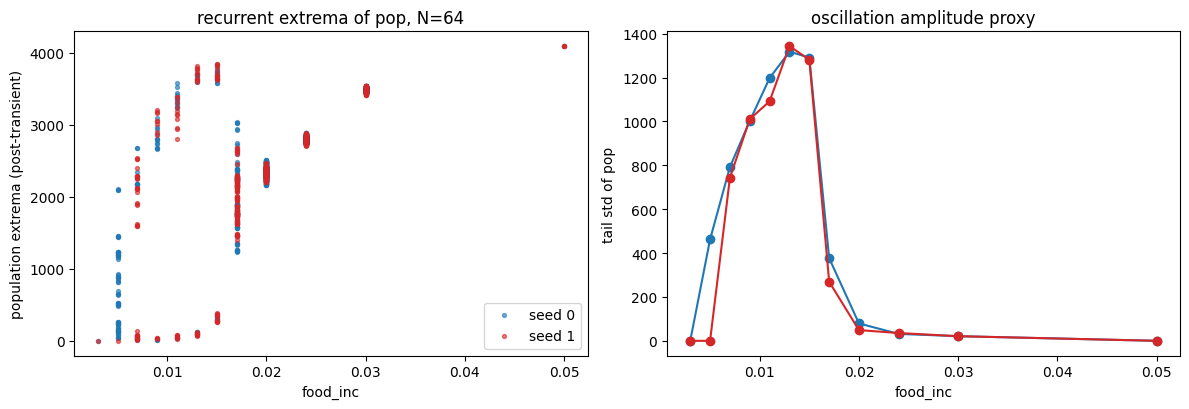

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for seed, col in ((0,'C0'), (1,'C3')):
    xs, ys = bif.to_scatter(res[seed])
    ax[0].scatter(xs, ys, s=8, c=col, alpha=.6, label=f'seed {seed}')
ax[0].set_xlabel('food_inc'); ax[0].set_ylabel('population extrema (post-transient)')
ax[0].set_title(f'recurrent extrema of pop, N={N}'); ax[0].legend()
for seed, col in ((0,'C0'), (1,'C3')):
    ax[1].plot([r['value'] for r in res[seed]], [r['series_tail_std'] for r in res[seed]], 'o-', c=col)
ax[1].set_xlabel('food_inc'); ax[1].set_ylabel('tail std of pop'); ax[1].set_title('oscillation amplitude proxy')
plt.tight_layout(); plt.show()

**Observed (N=64, seeds 0-1, example runs).** (i) Extinction: food_inc 0.003 in both seeds and 0.005 in seed 1, each at the first population crash after the initial boom (ticks 104-139, cell above), not after sustained cycling. (ii) 0.005-0.015: large boom-bust oscillations whose amplitude grows with `food_inc` (seed 0 tail std 462, 793, 1002, 1198, 1318, 1292 from 0.005 to 0.015), troughs at tens of cells (lowest extremum 15-98 up to 0.013, ~260-280 at 0.015) and peaks up to ~3850 of 4096. (iii) Between 0.015 and 0.017 the amplitude drops by a factor 3.4-4.8 (tail std 1292 -> 377 seed 0, 1282 -> 269 seed 1), and at 0.017 the extrema fill a band (~1240-3040) with no clear branches. (iv) 0.020-0.030: small fluctuations (std 79 -> 21) about a rising mean. (v) 0.050: pop pinned at N^2=4096. **No period-doubling-like branch structure is visible**; the diagram is "extinct / boom-bust of growing amplitude / sharp amplitude collapse near 0.016 / small fluctuations / saturated". The collapse is the most transition-like feature but is bracketed by two grid points only (CRIT-N1). The extrema count still does not classify the regimes (ISSUES CRIT-Q2).


### Time series at three representative values

Per-tick `pop` and `Phi` (energy dissipation per capita from `get_dissipation`), with births per tick, and, every 10 ticks, the Bedau-Packard `A_new` (count of real LUT-genome components with cumulative activity above the neutral shadow's p90, computed as in `evoca_explore.run_sim`) and `lut_div`. Values: 0.013 (boom-bust), 0.022 (small oscillation), 0.050 (saturated).

In [8]:
def record(food_inc, N=64, n_steps=3000, seed=0, a_every=10):
    p = dict(BASE, food_inc=food_inc)
    sim = ee.build_sim(p, N=N, seed=seed, init='halfplane')
    sim.neutral_enable()
    out = {k: [] for k in ('pop','phi','births','deaths')}
    out.update(t_a=[], a_new=[], lut_div=[])
    try:
        for t in range(n_steps):
            sim.step()
            d = sim.get_dissipation()
            out['pop'].append(d['alive']); out['phi'].append(d['phi'])
            out['births'].append(sim.get_births_last()); out['deaths'].append(sim.get_deaths_last())
            if t % a_every == 0:
                sim._lib.evoca_activity_update(); sim.n_activity_update()
                G = sim.get_activity(max_n=200000); Nt = sim.get_n_activity(max_n=200000)
                gp = G['pop_count'] > 0; npop = Nt['pop_count'] > 0
                n_acts = Nt['activity'][npop].astype(float)
                th = float(np.percentile(n_acts, 90)) if n_acts.size else 0.0
                out['a_new'].append(int((G['activity'][gp].astype(float) > th).sum()) if gp.any() else 0)
                out['lut_div'].append(int(gp.sum())); out['t_a'].append(t)
    finally:
        pass
    return sim, {k: np.array(v) for k, v in out.items()}

REP = {}
for fi in (0.013, 0.022, 0.050):
    t0 = time.time()
    sim, REP[fi] = record(fi)
    if fi == 0.013:
        sim_keep = sim   # keep for lattice snapshots + recipe
    else:
        sim.free()
    print(fi, 'done in %.1fs' % (time.time()-t0))

0.013 done in 0.6s


0.022 done in 0.8s


0.05 done in 1.2s


In [9]:
# The simulation may be run interactively with the following
# (commented out so that "Run All" does not block on the SDL window):
# from controls import run_with_controls
# sim = ee.build_sim(dict(BASE, food_inc=0.013), N=128, seed=0)   # boom-bust; also 0.022, 0.050
# run_with_controls(sim, cell_px=4, probes={'ts': True, 'activity': True})

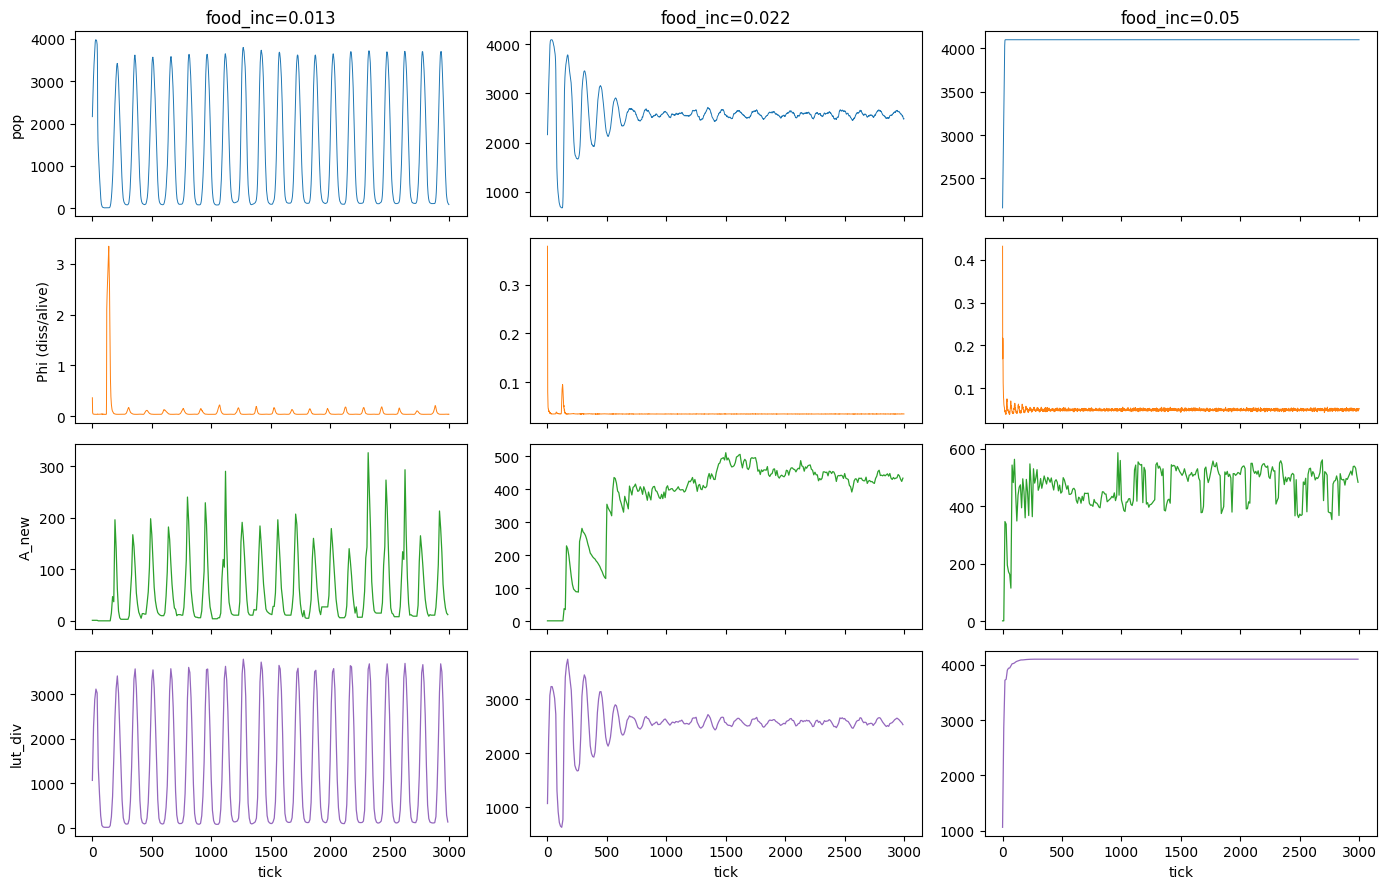

,food_inc,pop_mean,pop_std,dens_min,dens_max,phi_mean,phi_std,a_new_mean,acf_first_peak_lag
0,0.013,1308.996,1318.406,0.022,0.906,0.054,0.035,61.313,151.0
1,0.022,2572.065,48.966,0.598,0.651,0.035,0.000,450.213,143.0
2,0.050,4095.982,0.133,1.000,1.000,0.050,0.002,491.907,NaN


In [10]:
fig, axs = plt.subplots(4, 3, figsize=(14, 9), sharex=True)
for j, fi in enumerate(REP):
    R = REP[fi]; t = np.arange(len(R['pop']))
    axs[0,j].plot(t, R['pop'], lw=.7); axs[0,j].set_title(f'food_inc={fi}')
    axs[1,j].plot(t, R['phi'], lw=.7, c='C1')
    axs[2,j].plot(R['t_a'], R['a_new'], lw=.9, c='C2')
    axs[3,j].plot(R['t_a'], R['lut_div'], lw=.9, c='C4'); axs[3,j].set_xlabel('tick')
for i, l in enumerate(['pop', 'Phi (diss/alive)', 'A_new', 'lut_div']): axs[i,0].set_ylabel(l)
plt.tight_layout(); plt.show()
summ = []
for fi, R in REP.items():
    h = len(R['pop'])//2; x = R['pop'][h:].astype(float) - R['pop'][h:].mean()
    ac = np.correlate(x, x, 'full')[len(x)-1:]; ac = ac/ac[0] if ac[0] > 0 else ac
    pk = [i for i in range(5, len(ac)-1) if ac[i] > ac[i-1] and ac[i] >= ac[i+1] and ac[i] > 0.2]
    summ.append(dict(food_inc=fi, pop_mean=R['pop'][h:].mean(), pop_std=R['pop'][h:].std(),
                     dens_min=R['pop'][h:].min()/64**2, dens_max=R['pop'][h:].max()/64**2,
                     phi_mean=R['phi'][h:].mean(), phi_std=R['phi'][h:].std(),
                     a_new_mean=R['a_new'][len(R['a_new'])//2:].mean(), acf_first_peak_lag=(pk[0] if pk else None)))
display(pd.DataFrame(summ).round(3))

**Observed (N=64, seed 0, example runs).** At 0.013 the population runs a regular boom-bust cycle: autocorrelation first peak at lag 151, tail density between 0.022 and 0.906, peaks of nearly constant height (figure). Phi has mean 0.054 and std 0.035, with a spike at each crash; `A_new` has mean 61 and spikes at each boom. At 0.022 a damped oscillation decays over the first ~800 ticks into small fluctuations (density 0.598-0.651) that keep an autocorrelation peak at lag 143; Phi is pinned at the tax value (0.035, std 0.000: all intake is taxed away at steady state) and `A_new` is 450. At 0.050 pop sits at the lattice ceiling, Phi is 0.050, `A_new` is 492, and there is no autocorrelation peak. `A_new` is much lower in the boom-bust regime (repeated crashes) than in the steady ones, which suggests it, rather than pop extrema, may mark the regime change.

This is the run saved as recipe `Runs/2026-10-15_foodinc013_osc.evoca` (no `food_cap` key, so it loads capped). The Reaction-diffusion notebook's capped run of the same recipe at N=256 shows alive 0.03-0.75 with period ~150: the same period as here, with lower peaks than at N=64 (0.906). Lattice snapshots at a peak and a trough of the 0.013 run:


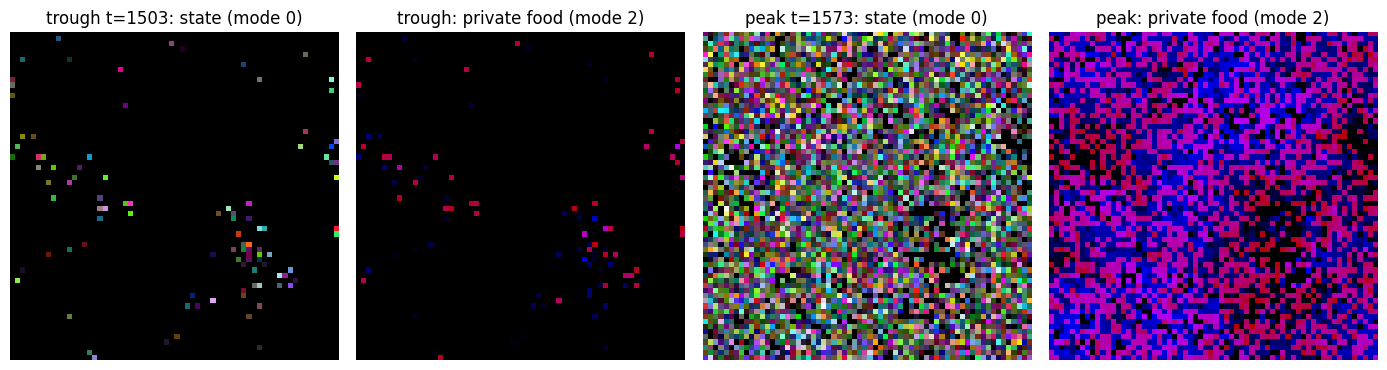

recipe: /private/tmp/evoca_food-cap-standard/Research/Criticality-bifurcation/Runs/2026-10-15_foodinc013_osc.evoca (recipe does not carry the seed; use seed 0 via build_sim for the exact series)


In [11]:
R = REP[0.013]; sim = sim_keep
fig, axs = plt.subplots(1, 4, figsize=(14, 3.6))
# re-run to a trough and a peak for snapshots
sim_keep.free()
sim = ee.build_sim(dict(BASE, food_inc=0.013), N=64, seed=0)
snaps = {}
want = {int(np.argmax(R['pop'][1500:2000]))+1500: 'peak', int(np.argmin(R['pop'][1500:2000]))+1500: 'trough'}
for t in range(2001):
    if t in want: snaps[want[t]] = (t, rgb(sim, 0), rgb(sim, 2))
    sim.step()
for i, (k, (t, s0, s2)) in enumerate(snaps.items()):
    axs[2*i].imshow(s0); axs[2*i].set_title(f'{k} t={t}: state (mode 0)')
    axs[2*i+1].imshow(s2); axs[2*i+1].set_title(f'{k}: private food (mode 2)')
for a in axs: a.axis('off')
plt.tight_layout(); plt.show()
fp = export_recipe_once(sim, 'foodinc013_osc', workstream=WS)   # reuses an existing copy
print('recipe:', fp, '(recipe does not carry the seed; use seed 0 via build_sim for the exact series)')
sim.free()

### N-dependence check (single-point, N = 32, 64, 128)

Is the oscillation a finite-size (synchronized-lattice) effect? Same parameters, `food_inc` in {0.016, 0.022}, seed 0, 3000 ticks. Reported as pop tail mean/std and *relative* amplitude std/mean.

In [12]:
rows = []
for fi in (0.016, 0.022):
    for n in (32, 64, 128):
        s = bif.scalar_series(dict(BASE, food_inc=fi), N=n, n_steps=3000, seed=0)
        tl = s[1500:]; rows.append(dict(food_inc=fi, N=n, mean_density=tl.mean()/n**2, std_density=tl.std()/n**2,
                                        rel_amp=tl.std()/max(tl.mean(),1), min_density=tl.min()/n**2))
nd = pd.DataFrame(rows).round(4); display(nd)

,food_inc,N,mean_density,std_density,rel_amp,min_density
0,0.016,32,0.4425,0.2522,0.5699,0.1650
1,0.016,64,0.4520,0.1788,0.3955,0.2017
2,0.016,128,0.4439,0.2174,0.4898,0.1785
3,0.022,32,0.6272,0.0256,0.0409,0.5596
4,0.022,64,0.6279,0.0120,0.0190,0.5984
5,0.022,128,0.6281,0.0061,0.0097,0.6123


**Observed (single seed, N=32/64/128; not replicated).** At food_inc 0.016 the oscillation does not average out: std/N^2 is 0.252, 0.179, 0.217 (relative amplitude 0.57, 0.40, 0.49), non-monotone in N with no downward trend to N=128. 0.016 sits between the large-amplitude 0.015 and the collapsed 0.017 columns, so its amplitude may be sensitive to where the collapse falls at each N; a value inside the boom-bust window (e.g. 0.013) would be a cleaner test. At 0.022 the relative amplitude is 0.041, 0.019, 0.0097, halving with each doubling of N, i.e. proportional to 1/N, as expected for independent local fluctuations summed over N^2 sites. So the large-amplitude regime looks intrinsic (a global synchronized cycle), and the small-amplitude regime looks like finite-size noise. This distinction is the content of ISSUES CRIT-Q1.


### Sanity check against R1

The R1 rescan (standard rule, N=256, 8000 ticks, varying tax / mu_lut / gdiff) has extinct fraction 0.23 at food_inc 0.005, 0.05 at 0.008, 0.11 at 0.010 and 0 from 0.013 at m_scale 3.5. Here (N=64, fixed tax 0.035 / mu_lut 0.06 / gdiff 0.06) 0.003 goes extinct in both seeds, 0.005 in one of two, and 0.007 up survive: consistent with a stochastic boundary near 0.005. Of R1's rows only one has exactly these tax/mu_lut/gdiff values with m_scale 3.5 (food_inc 0.005, below); in the rescan it survives (mean alive density 0.052, final pop 6092 of 65536), as seed 0 does here. A row-level comparison beyond that one point is not possible; the check is at the level of the extinction boundary.


In [13]:
sub = r1[(r1.param_m_scale==3.5)&(r1.param_tax==0.035)&(r1.param_mu_lut==0.06)&(r1.param_gdiff==0.06)]
display(sub[['param_food_inc','extinct','alive_density_mean','alive_density_temporal_std','final_pop']].sort_values('param_food_inc'))
print('elapsed so far %.0fs' % (time.time()-T0))

,param_food_inc,extinct,alive_density_mean,alive_density_temporal_std,final_pop
67,0.005,False,0.052325,0.057561,6092


elapsed so far 19s


## Current state and directions (2026-10-23)

- **State.** The harness is merged and has one example diagram, re-executed under the standard rule: along `food_inc` (m_scale 3.5, tax 0.035, mu_lut 0.06, gdiff 0.06, N=64, two seeds) the population goes extinct at 0.003 (and in one seed at 0.005) during the first crash, runs boom-bust cycles of growing amplitude from 0.005 to 0.015 (period ~150 ticks at 0.013), loses most of its amplitude between 0.015 and 0.017, fluctuates weakly from 0.020 to 0.030, and pins at the lattice ceiling by 0.05. No period-doubling signature is seen. A single-seed N-check (N=32-128) finds the boom-bust amplitude N-independent at 0.016 and the small-fluctuation amplitude scaling as 1/N at 0.022.
- **What the standard rule changed.** Under the legacy rule the same sweep went extinct at every food_inc <= 0.011 and its large-amplitude window was 0.013-0.017; the extinction boundary near 0.012 was a legacy artifact (final section).
- **Newly unblocked by the 2026-10-15 merges.** Observables beyond `pop`: Phi (`get_dissipation`), `A_new`, `dyn_activity`, lineage return are all on main, so a diagram can have several y-axes per column. The harness `sweep` records only `pop`/`activity`/`lut_div`, so adding Phi / A_new to `scalar_series` is a dev item (ISSUES CRIT-N2).
- **Decisions and directions.** See the ISSUES snapshot above (CRIT-D1: first control parameter and N; CRIT-D2: what counts as a transition; CRIT-N1..N6).


## Legacy rule (`food_cap=0`): results that depend on it

The legacy rule (uncapped mouthful) is not part of the model (N, 2026-10-23). This section only records how far the 2026-10-15 results moved. Every example run in this notebook has `m_scale` 3.5, where the cap binds. Below: the R1 extinction table as recorded (legacy) beside the rescan, and the 2026-10-15 example sweep re-run with `food_cap=0` beside the standard sweep. The legacy re-run reproduces the stored 2026-10-15 numbers (e.g. food_inc 0.013, seed 0: tail mean 1294.0, std 1344.3).


In [14]:
r1_leg = pd.read_csv(ROOT/'Research/Resource-driving/Scans/2026-05-18_R1_mscale_bracket/results.csv')   # recorded under the legacy rule
cmp = pd.concat({'legacy (recorded 2026-05-18)': r1_leg.groupby(['param_m_scale','param_food_inc']).extinct.mean().unstack(),
                 'standard (rescan 2026-10-23)': r1.groupby(['param_m_scale','param_food_inc']).extinct.mean().unstack()})
print('R1 extinct fraction by (m_scale, food_inc)'); display(cmp.round(2))


R1 extinct fraction by (m_scale, food_inc)


param_food_inc                              0.005  0.008  0.010  0.013  0.018
                             param_m_scale                                   
legacy (recorded 2026-05-18) 2.5             1.00   0.83   0.35   0.09    0.0
                             3.5             0.92   0.90   0.72   0.32    0.0
                             5.0             0.11   0.10   0.05   0.00    0.0
standard (rescan 2026-10-23) 2.5             0.48   0.17   0.00   0.00    0.0
                             3.5             0.23   0.05   0.11   0.00    0.0
                             5.0             0.37   0.05   0.00   0.00    0.0

In [15]:
# The 2026-10-15 example sweep re-run under the legacy rule (food_cap=0), seed 0, beside the standard sweep above.
LEG = dict(BASE, food_cap=0)
res_leg = bif.sweep('food_inc', VALUES, base_params=LEG, observable='pop', n_steps=NSTEPS, N=N, seed=0, transient_frac=0.5)
std0 = {r['value']: r for r in res[0]}
display(pd.DataFrame([dict(food_inc=r['value'],
                           legacy_mean=round(r['mean'],1), legacy_std=round(r['series_tail_std'],1), legacy_min=r['points'].min(),
                           standard_mean=round(std0[r['value']]['mean'],1), standard_std=round(std0[r['value']]['series_tail_std'],1),
                           standard_min=std0[r['value']]['points'].min()) for r in res_leg]))
rows = []
for n in (32, 64, 128):
    s = bif.scalar_series(dict(LEG, food_inc=0.016), N=n, n_steps=3000, seed=0)
    tl = s[1500:]; rows.append(dict(rule='legacy', food_inc=0.016, N=n, std_density=tl.std()/n**2, rel_amp=tl.std()/max(tl.mean(),1)))
display(pd.DataFrame(rows).round(4))
def acf_lag(s):
    x = s[1500:] - s[1500:].mean(); ac = np.correlate(x, x, 'full')[len(x)-1:]
    ac = ac/ac[0] if ac[0] > 0 else ac
    pk = [i for i in range(5, len(ac)-1) if ac[i] > ac[i-1] and ac[i] >= ac[i+1] and ac[i] > 0.2]
    return pk[0] if pk else None
print('autocorrelation first-peak lag, N=64, seed 0:')
for fi in (0.013, 0.022):
    print(f"  food_inc {fi}: legacy {acf_lag(bif.scalar_series(dict(LEG, food_inc=fi), N=64, n_steps=3000, seed=0))}, "
          f"standard {acf_lag(bif.scalar_series(dict(BASE, food_inc=fi), N=64, n_steps=3000, seed=0))}")
print('total elapsed %.0fs' % (time.time()-T0))


,food_inc,legacy_mean,legacy_std,legacy_min,standard_mean,standard_std,standard_min
0,0.003,0.0,0.0,0.000000,0.0,0.0,0.0
1,0.005,0.0,0.0,0.000000,556.6,462.4,33.0
2,0.007,0.0,0.0,0.000000,652.5,792.5,16.0
3,0.009,0.0,0.0,0.000000,860.2,1002.4,15.5
4,0.011,0.0,0.0,0.000000,1075.0,1198.2,36.0
5,0.013,1294.0,1344.3,11.833333,1308.2,1318.3,97.6
6,0.015,1594.7,1362.1,99.000000,1609.2,1291.5,278.0
7,0.017,1937.9,916.4,714.000000,1991.1,376.8,1238.0
8,0.020,2336.5,90.4,2148.000000,2338.3,79.4,2166.0
9,0.024,2801.8,47.9,2667.000000,2803.9,31.7,2725.0


,rule,food_inc,N,std_density,rel_amp
0,legacy,0.016,32,0.3351,0.7771
1,legacy,0.016,64,0.3183,0.7523
2,legacy,0.016,128,0.2972,0.6948


autocorrelation first-peak lag, N=64, seed 0:


  food_inc 0.013: legacy 128, standard 151


  food_inc 0.022: legacy 123, standard 143
total elapsed 28s


**Observed (legacy vs standard).**
- **R1.** At m_scale 3.5 the recorded (legacy) extinct fraction was 0.92 / 0.90 / 0.72 / 0.32 / 0 at food_inc 0.005 / 0.008 / 0.010 / 0.013 / 0.018; the rescan gives 0.23 / 0.05 / 0.11 / 0 / 0. The legacy U-shape in `m_scale` at food_inc 0.005 (1.00 / 0.92 / 0.11 at m_scale 2.5 / 3.5 / 5.0) becomes 0.48 / 0.23 / 0.37. The legacy rule's extra extinction came from eaters overdrawing their site and draining the next eater's private food.
- **Example sweep (N=64, seed 0).** Legacy goes extinct at every food_inc <= 0.011; standard survives down to 0.005 (0.007 in seed 1). The 2026-10-15 extinction boundary near 0.012 was therefore a legacy artifact. The large-amplitude window moves from 0.013-0.017 (legacy tail std 1344, 1362, 916) to 0.005-0.015, with the collapse now between 0.015 and 0.017 (standard std at 0.017: 377). Legacy troughs at 0.013 are deeper (lowest extremum 12 vs 98 cells). From 0.020 up the rules agree in tail mean to within 0.2% (e.g. 2336.5 vs 2338.3 at 0.020) and the standard fluctuations are somewhat smaller (std 79 vs 90 at 0.020, 32 vs 48 at 0.024).
- **Period.** Autocorrelation first-peak lag at N=64, seed 0: 128 (legacy) vs 151 (standard) at 0.013, and 123 vs 143 at 0.022. The ~150-tick period of `foodinc013_osc` is a standard-rule number; the legacy one was ~125.
- **N-check at 0.016.** Legacy std/N^2 0.335, 0.318, 0.297 (a slight decline with N); standard 0.252, 0.179, 0.217 (non-monotone). Both say the boom-bust amplitude does not average out up to N=128.
